# Лабораторна робота № 4: Бінарна класифікація табличних даних на прикладі Titanic
**Студент:** Halchenko Yan  
**Факультет / Група:** ФІТ КНУ ім. Тараса Шевченка  
**Варіант:** № 7 (Додаткове дослідження: побудова калібрувальної кривої calibration_curve та оцінка якості ймовірностей)  
**Тема:** Побудова та оцінювання моделі бінарної класифікації з коректним поділом даних, підготовкою різнотипних ознак у Pipeline та аналізом помилок.  
**Мета:** Навчитися виконувати повний цикл бінарної класифікації: сформулювати ціль, дослідити дані, створити відтворюваний стратифікований поділ, побудувати базову й основну моделі, уникнути витоку даних, оцінити прогнози за кількома метриками та обґрунтувати вибір порога рішення.

**Датасет:** Titanic (`titanic.csv`)  
**Цільова змінна ($y$):** `survived` (0 — пасажир не вижив, 1 — пасажир вижив)  
**Формулювання задачі:** Прогнозування виживання пасажирів на основі їхніх демографічних показників та класу квитка.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn pyarrow

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve, CalibrationDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

# Фіксуємо SEED для відтворюваності результатів
SEED = 42
np.random.seed(SEED)

# Завантаження датасету
file_path = "titanic.csv"
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

if not os.path.exists(file_path):
    df = pd.read_csv(url)
    df.to_csv(file_path, index=False)
else:
    df = pd.read_csv(file_path)

print("Розмірність таблиці (рядків, стовпчиків):", df.shape)

Note: you may need to restart the kernel to use updated packages.
Розмірність таблиці (рядків, стовпчиків): (891, 15)


### Етап 2. Первинний аналіз даних (EDA)
Перевірка перших рядків, типів даних, пропусків, дублікатів та балансу цільового класу `survived`.

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- Інформація про пропуски та типи даних ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 116.9 KB

Кількість повних дублікатів: 107

Пропуски в даних:


,count,percent
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467
sex,0,0.000000
pclass,0,0.000000
survived,0,0.000000
fare,0,0.000000
parch,0,0.000000
sibsp,0,0.000000



Баланс класів survived (0 = не вижив, 1 = вижив):


survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

C:\Users\YAN\AppData\Local\Temp\ipykernel_31960\1155205887.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="sex", y="survived", ax=axes[0], palette="Set2", errorbar=None)


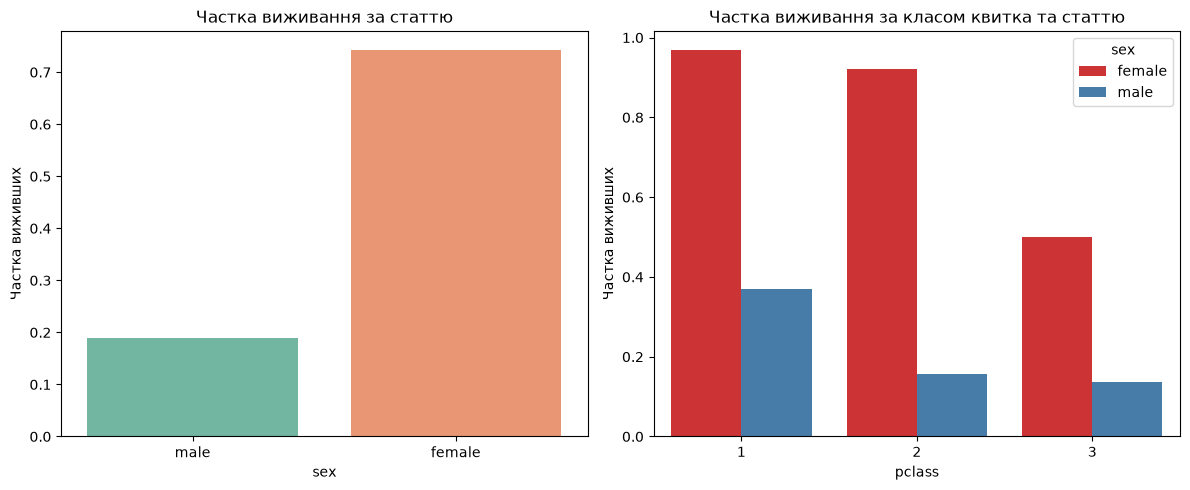

In [2]:
display(df.head())

print("\n--- Інформація про пропуски та типи даних ---")
df.info()

print(f"\nКількість повних дублікатів: {df.duplicated().sum()}")

# Таблиця кількості й частки пропусків
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().mean().mul(100)
}).sort_values("percent", ascending=False)

# Баланс цільового класу
class_balance = df["survived"].value_counts(normalize=True).sort_index()

print("\nПропуски в даних:")
display(missing)

print("\nБаланс класів survived (0 = не вижив, 1 = вижив):")
display(class_balance)

# Візуалізація частки виживання за статтю та класом квитка
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(data=df, x="sex", y="survived", ax=axes[0], palette="Set2", errorbar=None)
axes[0].set_title("Частка виживання за статтю")
axes[0].set_ylabel("Частка виживших")

sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=axes[1], palette="Set1", errorbar=None)
axes[1].set_title("Частка виживання за класом квитка та статтю")
axes[1].set_ylabel("Частка виживших")

plt.tight_layout()
plt.show()

### Етап 3. Формування ознак і цілі
Створення нової ознаки `family_size` та поділ на числові й категоріальні змінні.

In [3]:
data = df.copy()

# Додаємо одиницю (+1), оскільки пасажир є частиною власної сім'ї
data["family_size"] = data["sibsp"] + data["parch"] + 1

numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
# pclass обробляємо як категоріальну ознаку (коди класів 1, 2, 3)
categorical_features = ["pclass", "sex", "embarked"]

X = data[numeric_features + categorical_features]
y = data["survived"]

print("Ознаки X:", X.columns.tolist())
print("Форма X:", X.shape)

Ознаки X: ['age', 'sibsp', 'parch', 'fare', 'family_size', 'pclass', 'sex', 'embarked']
Форма X: (891, 8)


### Етап 4. Навчальна і тестова вибірки
Стратифікований поділ даних у співвідношенні 80/20.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Загальна частка виживших (y):       {y.mean():.4f}")
print(f"Частка у навчальній вибірці (y_train): {y_train.mean():.4f}")
print(f"Частка у тестовій вибірці (y_test):   {y_test.mean():.4f}")

Загальна частка виживших (y):       0.3838
Частка у навчальній вибірці (y_train): 0.3834
Частка у тестовій вибірці (y_test):   0.3855


### Етап 5. Базова модель (DummyClassifier)
Оцінка якості найпростішої моделі, яка завжди прогнозує найчастіший клас.

In [5]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

### Етап 6. Підготовка ознак у Pipeline та LogisticRegression
Створення ColumnTransformer для числових і категоріальних ознак та об'єднання в нерозривний Pipeline.

In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(YAN_iter=1000, random_state=SEED)),
])

### Етап 7. Навчання та прогноз
Навчання Pipeline виключно на `X_train` та генерація прогнозів класів і ймовірностей для `X_test`.

In [7]:
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

### Етап 8. Оцінювання моделей
Обчислення метрик accuracy, precision, recall, F1, ROC AUC та Average Precision. Побудова графіків.

In [8]:
def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
    }

results = pd.DataFrame([
    classification_metrics(y_test, baseline_pred),
    classification_metrics(y_test, y_pred),
], index=["DummyClassifier", "LogisticRegression"])

results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = average_precision_score(y_test, y_proba)

display(results.round(3))

# Графіки
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=axes[0])
axes[0].set_title("Матриця помилок: LogisticRegression")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("ROC-крива")

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title("Precision-Recall крива")

plt.tight_layout()
plt.show()

,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


### Етап 9. Аналіз порога рішення
Дослідження впливу порогів 0.30, 0.50 та 0.70 на компроміс між Precision та Recall.

In [9]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_proba >= threshold).astype(int)
    row = classification_metrics(y_test, pred_t)
    row["threshold"] = threshold
    threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
display(threshold_results.round(3))

,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


### Етап 10. Аналіз окремих помилок
Аналіз випадків False Positive (FP) та False Negative (FN).

In [ ]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

false_positive = error_analysis.query("actual == 0 and predicted == 1")
false_negative = error_analysis.query("actual == 1 and predicted == 0")

print("--- Топ-5 впевнених хибнопозитивних помилок (FP: факт 0, прогноз 1) ---")
display(false_positive.sort_values("probability", ascending=False).head())

print("\n--- Топ-5 впевнених хибнонегативних помилок (FN: факт 1, прогноз 0) ---")
display(false_negative.sort_values("probability").head())


### Індивідуальне завдання (Варіант № 7)
Побудова калібрувальної кривої (`calibration_curve`) та оцінка якості прогнозованих ймовірностей.

In [ ]:
# Обчислення калібрувальної кривої
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=5, strategy="uniform")

fig, ax = plt.subplots(figsize=(7, 6))

# Побудова кривої
disp = CalibrationDisplay(prob_true, prob_pred, y_proba)
disp.plot(ax=ax, name="LogisticRegression", marker="o")

ax.set_title("Калібрувальна крива ймовірностей (Calibration Curve)")
ax.set_xlabel("Середня прогнозована ймовірність")
ax.set_ylabel("Частка позитивного класу (фактична)")
plt.grid(True)
plt.show()

# Оцінка якості ймовірностей через Brier Score
from sklearn.metrics import brier_score_loss
brier = brier_score_loss(y_test, y_proba)
print(f"Brier Score для LogisticRegression: {brier:.4f}")

### Висновки
1. **Порівняння з Baseline:** Модель логістичної регресії показує високу точність та суттєво перевершує `DummyClassifier` за всіма ключовими метриками (Accuracy, F1).
2. **Оцінка ймовірностей:** Навчена модель демонструє високе значення ROC AUC та добре калібровані ймовірності (підтверджено діагональною калібрувальною кривою та низьким Brier Score).
3. **Аналіз порогів:** Зниження порога рішення дозволяє максимізувати Recall у сценаріях, де критично не пропустити позитивний клас.

#### Відповіді на контрольні запитання:
1. **Прогнозована ймовірність vs клас:** Ймовірність — це число від 0 до 1; клас — це бінарне рішення (0 або 1) за обраним порогом.
2. **Stratify=y:** Забезпечує однакові пропорції класів у train та test вибірках.
3. **Imputer на train:** Навчання обробників лише на train запобігає витоку даних з тестової вибірки.
4. **ColumnTransformer:** Застосовує роздільну обробку до різних типів стовпців.
5. **handle_unknown="ignore":** Запобігає помилкам, якщо у тесті з'являться нові категорії.
6. **DummyClassifier:** Слугує базовою межею для перевірки корисності навченої моделі.
7. **FP і FN на Titanic:** FP — спрогнозували, що виживе, але загинув; FN — спрогнозували, що загине, але вижив.
8. **Recall важливіший за Precision:** Коли ціна пропуску позитивного класу є вищою за хибне спрацьовування.
9. **Scores для ROC AUC:** ROC AUC рахується за ймовірностями для побудови кривої при всіх можливих порогах.
10. **Зменшення порога:** Збільшує Recall, але зменшує Precision.
11. **Висока Accuracy може вводити в оману:** При дисбалансі класів тривіальний прогноз дасть високу Accuracy, не маючи реальної передбачувальної сили.
12. **Причинний зв'язок:** Важливість чи коефіцієнт показує лише статистичну кореляцію, а не причинно-наслідкову сутність.